# SolarScan: apoyo a la inspección visual de paneles fotovoltaicos
## Preparación de datos, evaluación del modelo y desarrollo del servicio de inferencia

La revisión de fotografías permite identificar condiciones de los paneles que requieren atención, pero su interpretación depende del criterio del inspector y del tiempo disponible. SolarScan aborda esta tarea mediante un clasificador de imágenes dirigido al encargado de Operación y Mantenimiento de una planta fotovoltaica.

El proyecto considera seis condiciones: panel limpio, presencia de polvo, excrementos de aves, cobertura de nieve, daño físico y apariencia asociada a daño eléctrico. A partir de la clasificación, se establece una acción orientativa de seguimiento, limpieza o inspección técnica. La decisión final permanece a cargo del personal responsable.

Este trabajo presenta la preparación del dataset, el entrenamiento de EfficientNet-B0 y su comparación con un método sencillo basado en características visuales. Posteriormente, se analiza el efecto de los errores sobre las decisiones de mantenimiento y se prepara un servicio para utilizar el modelo fuera del entorno de entrenamiento. La integración con n8n se contempla como una fase posterior.

El alcance se limita a la información visible en las fotografías. La clasificación no permite confirmar el funcionamiento eléctrico del panel ni estimar pérdidas de generación.


In [ ]:
%pip -q install kagglehub timm pillow pandas scikit-learn scipy matplotlib joblib

In [ ]:
import json, random, time, shutil, hashlib, platform
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, timm
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display
SEMILLA=42
random.seed(SEMILLA);np.random.seed(SEMILLA);torch.manual_seed(SEMILLA)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEMILLA)
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True
DISP='cuda' if torch.cuda.is_available() else 'cpu'
print('Dispositivo:',DISP)
if DISP=='cpu':print('Activa GPU T4 antes de entrenar; la CPU será mucho más lenta.')
OUT=Path('SolarScan_'+datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
OUT.mkdir();print('Resultados:',OUT)


Dispositivo: cuda
Resultados: SolarScan_20261107_022437_504299


## 1. Obtención de los datos

Se utiliza el dataset *Solar Panel Images Clean and Faulty Images*, publicado en Kaggle por pythonafroz. La descarga se realiza mediante KaggleHub y las imágenes se leen directamente desde la carpeta de origen. Este procedimiento evita duplicar archivos y aprovecha la caché del entorno durante las ejecuciones sucesivas.

El inventario conserva la ubicación y los hashes de las imágenes para identificar el contenido utilizado en el análisis.


In [ ]:
import kagglehub
from pathlib import Path
path = kagglehub.dataset_download("pythonafroz/solar-panel-images")
DATA_ROOT = Path(path)
print("Dataset listo en:", DATA_ROOT)


Using Colab cache for faster access to the 'solar-panel-images' dataset.
Dataset listo en: /kaggle/input/solar-panel-images


## 2. Revisión y organización del dataset

Antes de entrenar el modelo, se comprueba la integridad de las imágenes y se revisa su distribución por clase. La depuración utiliza hashes del archivo, del contenido RGB y de similitud perceptual para identificar copias y escenas relacionadas. Se conserva una copia de cada contenido idéntico y se excluyen los grupos que presentan etiquetas contradictorias.

Las imágenes se distribuyen aproximadamente en 70 % para entrenamiento, 15 % para validación y 15 % para prueba, con semilla 42. Los grupos de imágenes similares se mantienen en un mismo subconjunto para reducir la posibilidad de evaluar el modelo con escenas que ya haya observado durante el entrenamiento.

El dataset no proporciona identificadores de planta, panel o sesión fotográfica. Por esta razón, la separación por similitud reduce el riesgo de duplicación, aunque no demuestra independencia entre instalaciones.

**Fuente:** [Solar Panel Images — Kaggle](https://www.kaggle.com/datasets/pythonafroz/solar-panel-images). La licencia consultada figura como “Unknown”; esta falta de especificación se registra como una limitación documental.


In [ ]:
"""Auditoría sin copiar imágenes; pHash vectorizado y grupos antes del split."""
import hashlib, json
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image, ImageOps, ImageDraw
from scipy.fft import dctn
CLASES=['Bird-drop','Clean','Dusty','Electrical-damage','Physical-Damage','Snow-Covered']
EXT={'.jpg','.jpeg','.png','.bmp','.webp'}

def preparar_dataset_rapido(data_root, out):
    data_root=Path(data_root);out=Path(out);out.mkdir(parents=True,exist_ok=True)
    rows=[];thumbs={};bits={}
    for p in sorted(data_root.rglob('*')):
        if not p.is_file() or p.suffix.lower() not in EXT:continue
        c=next((s for s in p.relative_to(data_root).parts[:-1] if s in CLASES),None)
        if c is None:continue
        i=len(rows);r=dict(id=i,ruta=str(p),ruta_relativa=str(p.relative_to(data_root)),clase=c,estado='valida',error='')
        try:
            r['sha256']=hashlib.sha256(p.read_bytes()).hexdigest()
            with Image.open(p) as im:im.verify()
            with Image.open(p) as im:
                im.load();rgb=ImageOps.exif_transpose(im).convert('RGB')
                r.update(ancho=rgb.width,alto=rgb.height)
                r['pixel_sha256']=hashlib.sha256(str(rgb.size).encode()+rgb.tobytes()).hexdigest()
                d=dctn(np.asarray(rgb.convert('L').resize((32,32)),dtype=float),type=2,norm='ortho')[:8,:8].flatten()
                bits[i]=d>np.median(d[1:]);thumbs[i]=ImageOps.contain(rgb,(140,100))
        except Exception as e:r.update(estado='no_utilizable',error=str(e))
        rows.append(r)
    if not rows:raise ValueError('No se encontraron imágenes de las seis clases.')
    df=pd.DataFrame(rows);df['motivo']=df.estado;df['split']='excluida';df['grupo']=''
    ids=df.index[df.estado.eq('valida')].tolist();parent={i:i for i in ids}
    def root(i):
        while parent[i]!=i:parent[i]=parent[parent[i]];i=parent[i]
        return i
    pares=[];arr=np.stack([bits[i] for i in ids])
    # Operaciones NumPy en lugar de acceder a pandas para cada par.
    # O(n²), pero sin matriz gigante; apropiado para este dataset pequeño.
    for k,i in enumerate(ids):
        dist=np.count_nonzero(arr[k+1:]!=arr[k],axis=1)
        for offset in np.flatnonzero(dist<=6):
            j=ids[k+1+int(offset)];parent[root(j)]=root(i)
            pares.append((i,j,int(dist[offset])))
    # Garantía explícita de agrupación por contenido idéntico.
    for _,g in df.loc[ids].groupby('pixel_sha256'):
        for j in g.index[1:]:parent[root(j)]=root(g.index[0])
    for i in ids:df.at[i,'grupo']=f'g{root(i):04d}'
    for _,g in df.loc[ids].groupby('grupo'):
        if g.clase.nunique()>1:df.loc[g.index,'motivo']='cuarentena_multiclase';continue
        dup=g.duplicated('pixel_sha256')
        df.loc[g.index[dup],'motivo']='duplicado_exacto'
        df.loc[g.index[~dup],'motivo']='incluida'
    rng=np.random.default_rng(42)
    for c in CLASES:
        sub=df[df.clase.eq(c)&df.motivo.eq('incluida')]
        groups=list(sub.groupby('grupo').groups.items());rng.shuffle(groups);groups.sort(key=lambda g:-len(g[1]))
        objetivo=np.array([.7,.15,.15])*len(sub);actual=np.zeros(3)
        for _,idx in groups:
            k=int(np.argmax(objetivo-actual));df.loc[idx,'split']=['train','val','test'][k];actual[k]+=len(idx)
    elegido=df[df.motivo.eq('incluida')].copy()
    assert elegido.groupby('grupo').split.nunique().max()==1
    assert elegido.groupby('pixel_sha256').split.nunique().max()==1
    for c in CLASES:assert set(elegido[elegido.clase.eq(c)].split)=={'train','val','test'},f'Faltan datos: {c}'
    df.to_csv(out/'inventario_completo.csv',index=False);elegido.to_csv(out/'inventario_utilizado.csv',index=False)
    pd.DataFrame(pares,columns=['id_a','id_b','distancia_phash']).to_csv(out/'pares_similares.csv',index=False)
    dist=pd.crosstab(elegido.clase,elegido.split).reindex(CLASES)[['train','val','test']];dist['total']=dist.sum(axis=1);dist.to_csv(out/'distribucion.csv')
    resumen={'encontradas':len(df),'incluidas':len(elegido),'motivos':df.motivo.value_counts().to_dict(),'semilla':42,'phash_distancia_max':6,'data_root':str(data_root),'limite':'pHash no garantiza independencia por planta, panel o sesión.'}
    (out/'resumen.json').write_text(json.dumps(resumen,indent=2,ensure_ascii=False))
    for c in CLASES:
        muestra=elegido.index[elegido.clase.eq(c)&elegido.split.eq('train')].tolist()[:20]
        canvas=Image.new('RGB',(850,550),'white');draw=ImageDraw.Draw(canvas);draw.text((8,8),c+' | solo train',fill='black')
        for k,i in enumerate(muestra):
            x=k%5*170;y=k//5*130+30;canvas.paste(thumbs[i],(x,y));draw.text((x,y+102),f'ID {i}',fill='black')
        canvas.save(out/f'contacto_{c}.jpg')
    print(json.dumps(resumen,indent=2,ensure_ascii=False));print(dist)
    return elegido


{
  "encontradas": 885,
  "incluidas": 787,
  "motivos": {
    "incluida": 787,
    "duplicado_exacto": 87,
    "cuarentena_multiclase": 11
  },
  "semilla": 42,
  "phash_distancia_max": 6,
  "data_root": "/kaggle/input/solar-panel-images",
  "limite": "pHash no garantiza independencia por planta, panel o sesión."
}
split              train  val  test  total
clase                                     
Bird-drop            108   23    23    154
Clean                129   28    28    185
Dusty                128   27    27    182
Electrical-damage     64   14    13     91
Physical-Damage       44    9     9     62
Snow-Covered          79   17    17    113


,clase,train,val,test,total
0,Bird-drop,108,23,23,154
1,Clean,129,28,28,185
2,Dusty,128,27,27,182
3,Electrical-damage,64,14,13,91
4,Physical-Damage,44,9,9,62
5,Snow-Covered,79,17,17,113


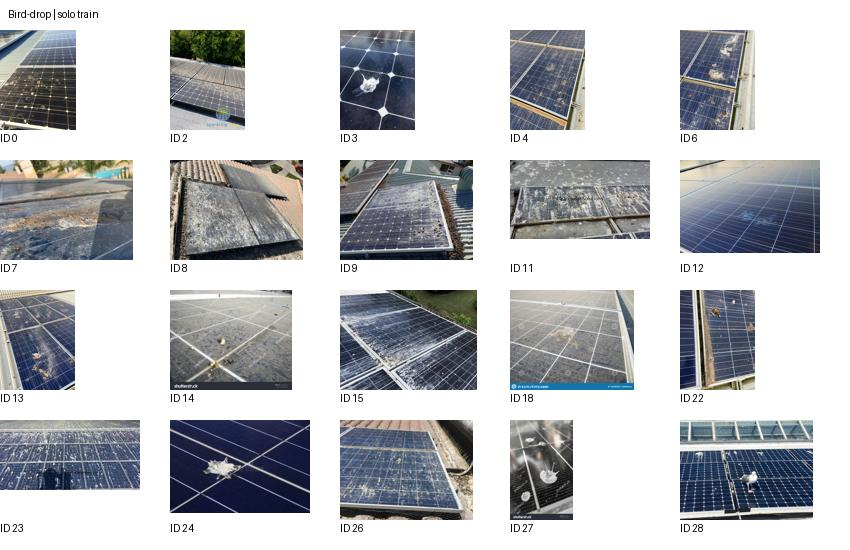

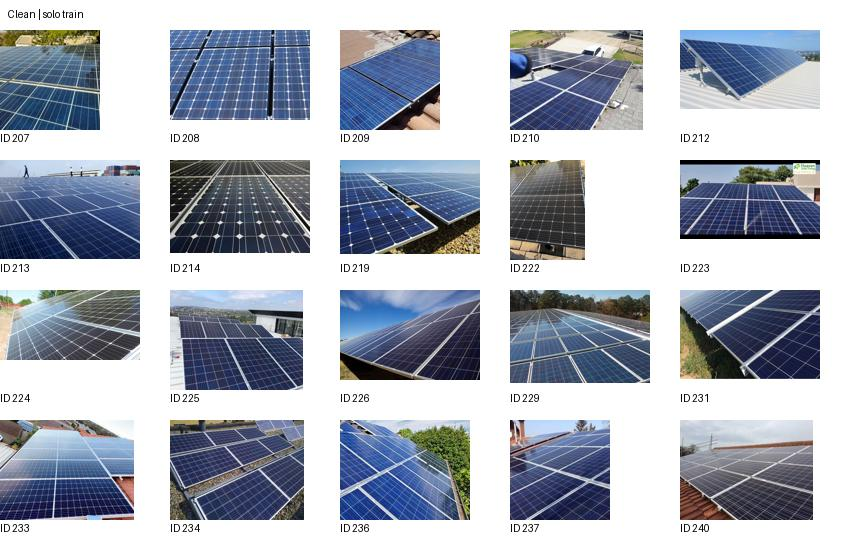

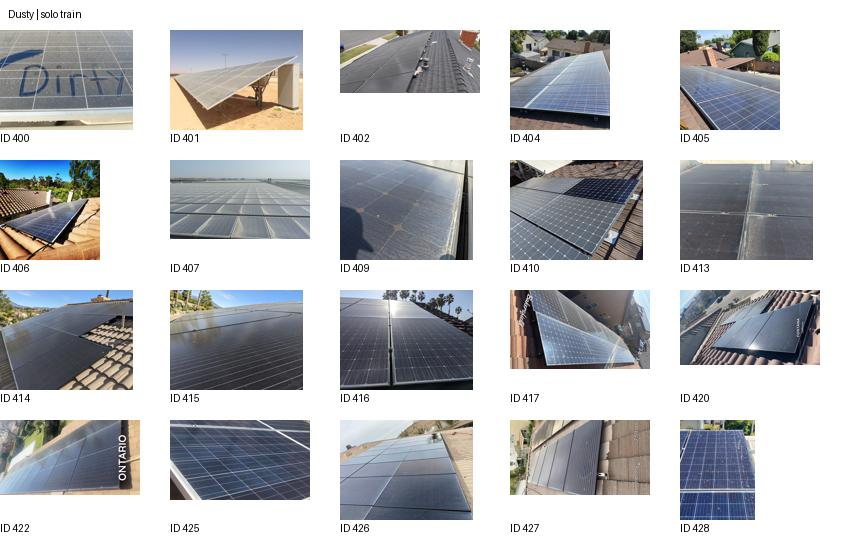

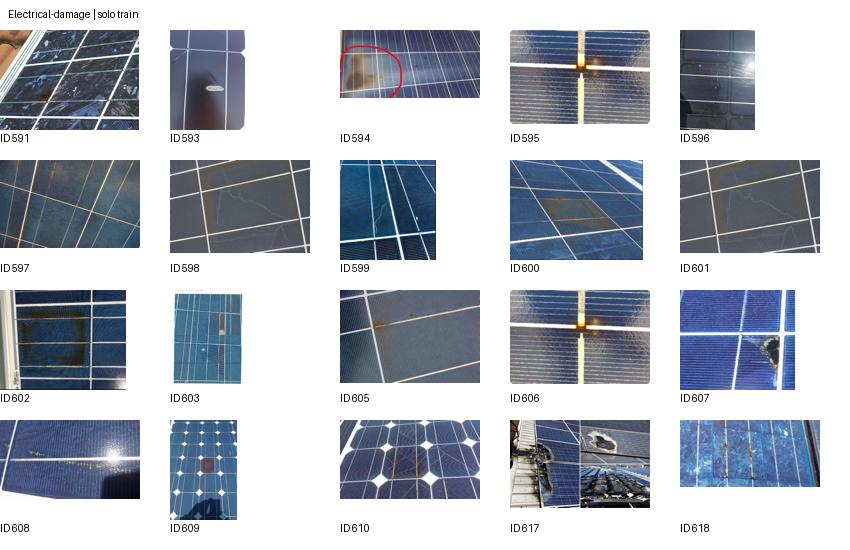

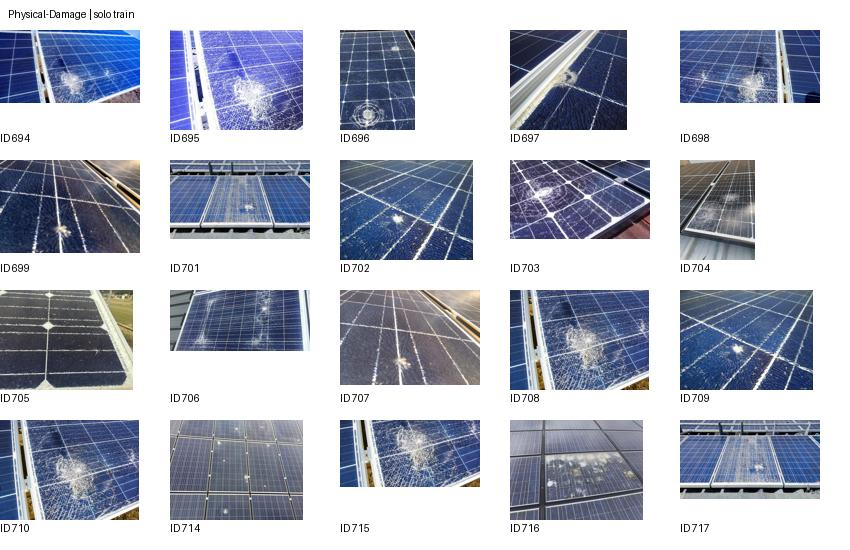

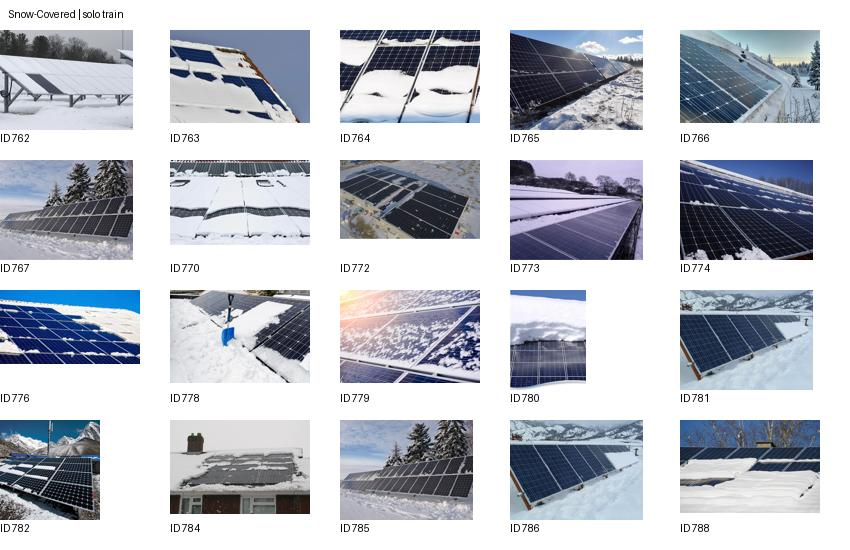

In [ ]:
dataset_limpio=preparar_dataset_rapido(DATA_ROOT, OUT/'datos')
CLASE_A_ID={c:i for i,c in enumerate(CLASES)}
partes={s:dataset_limpio[dataset_limpio.split.eq(s)].reset_index(drop=True) for s in ['train','val','test']}
for s,df in partes.items():
    assert all(Path(p).is_file() for p in df.ruta)
    assert set(df.clase)==set(CLASES)
display(pd.read_csv(OUT/'datos/distribucion.csv'))
for clase in CLASES:display(Image.open(OUT/'datos'/f'contacto_{clase}.jpg'))


## 3. Preparación de las imágenes

Las imágenes se orientan según su información EXIF, se convierten a RGB y se ajustan a 224 × 224 píxeles. Se utiliza relleno gris para conservar la proporción y mantener visibles los bordes del panel, donde también pueden aparecer daños. La normalización corresponde a los parámetros del modelo preentrenado.

Durante el entrenamiento se aplican volteos horizontales y variaciones moderadas de brillo y contraste. Estas transformaciones aumentan la variedad de ejemplos sin alterar deliberadamente la condición representada. Para validación, prueba e inferencia se utiliza el mismo procesamiento, sin aumentos aleatorios.


In [ ]:
INFERENCIA_SRC = '"""Inferencia reutilizable; no requiere acceso a Kaggle ni descarga de pesos."""\nimport json\nfrom pathlib import Path\nimport torch\nimport timm\nfrom PIL import Image, ImageOps\nfrom torchvision import transforms\n\nclass AjustarCuadrado:\n    """Conservar toda la imagen y su proporción; rellenar márgenes con gris."""\n    def __init__(self,tam=224):self.tam=tam\n    def __call__(self,im):\n        return ImageOps.pad(im,(self.tam,self.tam),method=Image.Resampling.BILINEAR,color=(128,128,128))\n\ndef abrir_rgb(ruta):\n    with Image.open(ruta) as im:\n        im.load();return ImageOps.exif_transpose(im).convert(\'RGB\')\n\ndef transformacion_eval(config):\n    return transforms.Compose([AjustarCuadrado(config[\'tam\']),transforms.ToTensor(),transforms.Normalize(config[\'media\'],config[\'desv\'])])\n\ndef cargar_modelo(carpeta,dispositivo=\'cpu\'):\n    carpeta=Path(carpeta);config=json.loads((carpeta/\'config.json\').read_text())\n    modelo=timm.create_model(config[\'arquitectura\'],pretrained=False,num_classes=len(config[\'clases\']))\n    modelo.load_state_dict(torch.load(carpeta/\'efficientnet_b0_solar.pt\',map_location=\'cpu\',weights_only=True))\n    return modelo.to(dispositivo).eval(),config,transformacion_eval(config)\n\ndef predecir(ruta,modelo,config,tf,dispositivo=\'cpu\'):\n    x=tf(abrir_rgb(ruta)).unsqueeze(0).to(dispositivo)\n    with torch.inference_mode():p=torch.softmax(modelo(x),dim=1)[0].cpu()\n    i=int(p.argmax());clase=config[\'clases\'][i];conf=float(p[i])\n    baja=conf<config[\'umbral_revision\']\n    return {\'clase\':clase,\'confianza\':conf,\'baja_confianza\':baja,\n            \'revision_humana\':baja or clase in [\'Electrical-damage\',\'Physical-Damage\'],\n            \'probabilidades\':{c:float(p[k]) for k,c in enumerate(config[\'clases\'])},\n            \'nota\':\'Puntaje softmax no calibrado; no confirma una falla eléctrica.\'}\n'
Path('inferencia_solar.py').write_text(INFERENCIA_SRC,encoding='utf-8')
from inferencia_solar import AjustarCuadrado, abrir_rgb, transformacion_eval, cargar_modelo, predecir


In [ ]:
ARQUITECTURA='efficientnet_b0'
modelo=timm.create_model(ARQUITECTURA,pretrained=True,num_classes=len(CLASES)).to(DISP)
TAM=224
MEDIA=list(modelo.pretrained_cfg['mean']);DESV=list(modelo.pretrained_cfg['std'])
CONFIG_BASE={'arquitectura':ARQUITECTURA,'clases':CLASES,'tam':TAM,'media':MEDIA,'desv':DESV}
tf_eval=transformacion_eval(CONFIG_BASE)
tf_train=transforms.Compose([AjustarCuadrado(TAM),transforms.RandomHorizontalFlip(p=.5),
    transforms.ColorJitter(brightness=.1,contrast=.1),transforms.ToTensor(),transforms.Normalize(MEDIA,DESV)])
class PanelesDataset(Dataset):
    def __init__(self,df,transform):self.df=df.reset_index(drop=True);self.transform=transform
    def __len__(self):return len(self.df)
    def __getitem__(self,i):
        r=self.df.iloc[i]
        return self.transform(abrir_rgb(r.ruta)),CLASE_A_ID[r.clase]
# num_workers=0 facilita reproducibilidad y evita problemas de procesos en Colab.
generador=torch.Generator().manual_seed(SEMILLA)
dl_train=DataLoader(PanelesDataset(partes['train'],tf_train),batch_size=32,shuffle=True,num_workers=0,generator=generador)
dl_val=DataLoader(PanelesDataset(partes['val'],tf_eval),batch_size=64,shuffle=False,num_workers=0)
LABELS=list(range(len(CLASES)))
def metricas(y,pred):
    return {'accuracy':float(accuracy_score(y,pred)),
            'accuracy_balanceada':float(balanced_accuracy_score(y,pred)),
            'macro_f1':float(f1_score(y,pred,labels=LABELS,average='macro',zero_division=0))}
@torch.inference_mode()
def inferir_loader(red,loader):
    red.eval();probs=[];ys=[]
    for x,y in loader:
        probs.append(torch.softmax(red(x.to(DISP)),dim=1).cpu().numpy());ys.extend(y.numpy().tolist())
    return np.array(ys),np.concatenate(probs)
print('Clases:',CLASE_A_ID)


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Clases: {'Bird-drop': 0, 'Clean': 1, 'Dusty': 2, 'Electrical-damage': 3, 'Physical-Damage': 4, 'Snow-Covered': 5}


## 4. Método de referencia

Para evaluar el aporte del modelo preentrenado, se incorpora un árbol de decisión que utiliza cinco características de la imagen: brillo, contraste, saturación, proporción de píxeles claros y variación entre píxeles vecinos. El árbol genera reglas de umbral que permiten explicar cómo se obtiene cada clasificación.

Las reglas se ajustan con entrenamiento. Se comparan profundidades máximas de dos y tres mediante macro-F1 de validación y, en caso de empate, se conserva el árbol más sencillo. El conjunto de prueba queda reservado para la comparación final de ambos métodos.


In [ ]:
from sklearn.tree import DecisionTreeClassifier, export_text
import joblib
FEATURES=['brillo','contraste','saturacion','fraccion_clara','cambios_vecinos']
def caracteristicas(ruta):
    im=abrir_rgb(ruta).resize((64,64),Image.Resampling.BILINEAR)
    g=np.asarray(im.convert('L'),dtype=np.float32)/255
    hsv=np.asarray(im.convert('HSV'),dtype=np.float32)/255
    return [g.mean(),g.std(),hsv[:,:,1].mean(),(g>.8).mean(),
            (np.abs(np.diff(g,axis=0)).mean()+np.abs(np.diff(g,axis=1)).mean())/2]
Xtr=np.array([caracteristicas(p) for p in partes['train'].ruta])
Xva=np.array([caracteristicas(p) for p in partes['val'].ruta])
ytr=partes['train'].clase.map(CLASE_A_ID).to_numpy();yva=partes['val'].clase.map(CLASE_A_ID).to_numpy()
candidatos=[]
for profundidad in [2,3]:
    arbol=DecisionTreeClassifier(max_depth=profundidad,min_samples_leaf=10,class_weight='balanced',random_state=SEMILLA)
    arbol.fit(Xtr,ytr);m=metricas(yva,arbol.predict(Xva));candidatos.append((m['macro_f1'],profundidad,arbol,m))
# En empate preferimos la menor profundidad.
_,profundidad,baseline,metricas_baseline_val=max(candidatos,key=lambda t:(t[0],-t[1]))
display(pd.DataFrame([{'profundidad':d,**m} for _,d,_,m in candidatos]))
reglas=export_text(baseline,feature_names=FEATURES);print(reglas)
(OUT/'reglas_baseline.txt').write_text(reglas)
joblib.dump(baseline,OUT/'baseline_arbol.joblib')


,profundidad,accuracy,accuracy_balanceada,macro_f1
0,2,0.313559,0.372186,0.219048
1,3,0.381356,0.391874,0.331550


|--- fraccion_clara <= 0.18
|   |--- cambios_vecinos <= 0.05
|   |   |--- brillo <= 0.42
|   |   |   |--- class: 3
|   |   |--- brillo >  0.42
|   |   |   |--- class: 2
|   |--- cambios_vecinos >  0.05
|   |   |--- saturacion <= 0.28
|   |   |   |--- class: 0
|   |   |--- saturacion >  0.28
|   |   |   |--- class: 4
|--- fraccion_clara >  0.18
|   |--- cambios_vecinos <= 0.03
|   |   |--- class: 5
|   |--- cambios_vecinos >  0.03
|   |   |--- fraccion_clara <= 0.23
|   |   |   |--- class: 5
|   |   |--- fraccion_clara >  0.23
|   |   |   |--- class: 5



['SolarScan_20261107_022437_504299/baseline_arbol.joblib']

## 5. Entrenamiento de EfficientNet-B0

Se selecciona EfficientNet-B0 para aprovechar las características visuales aprendidas durante su preentrenamiento. La capa de salida se adapta a las seis clases del proyecto y la red se ajusta con las imágenes solares mediante el optimizador AdamW.

La función de pérdida pondera las clases según sus frecuencias en entrenamiento. De esta forma, las categorías con menos ejemplos tienen mayor peso en el ajuste, sin alterar la composición de validación y prueba.

El entrenamiento considera un máximo de diez épocas y se detiene si transcurren tres sin mejora. Se conserva el modelo con mayor macro-F1 de validación; si existe empate, se utiliza la menor pérdida de validación. Para cada imagen, la predicción corresponde a la clase con mayor puntaje softmax.


Época 1: train=2.5294, val=1.6237, macro-F1=0.519
Época 2: train=0.5930, val=1.0965, macro-F1=0.676
Época 3: train=0.2466, val=1.0611, macro-F1=0.691
Época 4: train=0.1163, val=1.0077, macro-F1=0.744
Época 5: train=0.0828, val=0.9366, macro-F1=0.761
Época 6: train=0.0644, val=0.9024, macro-F1=0.741
Época 7: train=0.0541, val=0.8332, macro-F1=0.736
Época 8: train=0.0362, val=0.8342, macro-F1=0.768
Época 9: train=0.0323, val=0.8304, macro-F1=0.792
Época 10: train=0.0280, val=0.7760, macro-F1=0.786


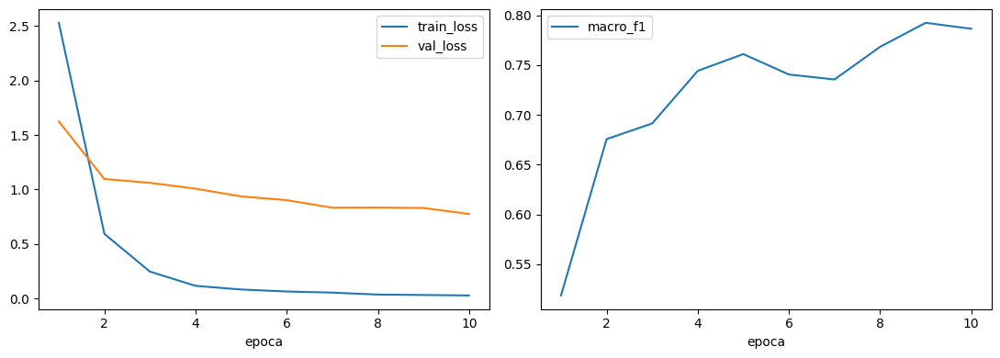

In [ ]:
# Obtener etiquetas directamente de train: no depender de la celda del baseline.
ytr = partes['train']['clase'].map(CLASE_A_ID).to_numpy(dtype=np.int64)
assert len(ytr) > 0, 'El conjunto de entrenamiento está vacío.'
assert set(ytr) == set(range(len(CLASES))), 'Faltan clases en entrenamiento.'
EPOCAS=10;PACIENCIA=3
conteos=np.bincount(ytr,minlength=len(CLASES))
pesos=len(ytr)/(len(CLASES)*conteos)
perdida=torch.nn.CrossEntropyLoss(weight=torch.tensor(pesos,dtype=torch.float32,device=DISP))
opt=torch.optim.AdamW(modelo.parameters(),lr=1e-4,weight_decay=1e-4)
mejor_f1=-1.;mejor_loss=float('inf');sin_mejora=0;historia=[]
CHECKPOINT=OUT/'mejor_efficientnet_b0_solar.pt'
for epoca in range(1,EPOCAS+1):
    modelo.train();total=0.;den=0.
    for x,y in dl_train:
        x=x.to(DISP);y=y.to(DISP);opt.zero_grad(set_to_none=True)
        loss=perdida(modelo(x),y);loss.backward();opt.step()
        w=perdida.weight[y].sum().item();total+=loss.item()*w;den+=w
    modelo.eval();vtotal=0.;vden=0.;probs=[];reales=[]
    with torch.inference_mode():
        for x,y in dl_val:
            x=x.to(DISP);y=y.to(DISP);logits=modelo(x);loss=perdida(logits,y)
            w=perdida.weight[y].sum().item();vtotal+=loss.item()*w;vden+=w
            probs.append(torch.softmax(logits,dim=1).cpu().numpy());reales.extend(y.cpu().tolist())
    m=metricas(np.array(reales),np.concatenate(probs).argmax(1));vl=vtotal/vden
    historia.append({'epoca':epoca,'train_loss':total/den,'val_loss':vl,**m})
    print(f"Época {epoca}: train={total/den:.4f}, val={vl:.4f}, macro-F1={m['macro_f1']:.3f}")
    mejora=m['macro_f1']>mejor_f1+1e-8 or (abs(m['macro_f1']-mejor_f1)<=1e-8 and vl<mejor_loss)
    if mejora:
        mejor_f1=m['macro_f1'];mejor_loss=vl;MEJOR_EPOCA=epoca;sin_mejora=0
        torch.save(modelo.state_dict(),CHECKPOINT)
    else:sin_mejora+=1
    if sin_mejora>=PACIENCIA:print('Parada temprana');break
modelo.load_state_dict(torch.load(CHECKPOINT,map_location=DISP,weights_only=True));modelo.eval()
hist=pd.DataFrame(historia);hist.to_csv(OUT/'historia.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(11,4))
hist.plot(x='epoca',y=['train_loss','val_loss'],ax=ax[0]);hist.plot(x='epoca',y='macro_f1',ax=ax[1]);plt.tight_layout();plt.savefig(OUT/'aprendizaje.png');plt.show()


## 6. Selección del modelo y revisión humana

La selección se realiza mediante macro-F1 de validación, métrica que permite considerar el desempeño de las seis clases sin que las más numerosas dominen el resultado. Este criterio se aplica antes de la evaluación en prueba.

Como política inicial de operación, las predicciones con puntaje inferior a 0,70 se derivan a revisión humana. Las clasificaciones de daño físico o eléctrico requieren inspección técnica independientemente del puntaje. El umbral se establece como un supuesto del prototipo y no se modifica en función de los resultados de prueba.

El puntaje softmax expresa la preferencia del modelo entre las clases disponibles. Al no estar calibrado, no debe interpretarse como una garantía de acierto ni como una confirmación de que la imagen pertenece al dominio del proyecto.


In [ ]:
yv,pv=inferir_loader(modelo,dl_val)
metricas_eff_val=metricas(yv,pv.argmax(1))
comparacion_val=pd.DataFrame({'EfficientNet-B0':metricas_eff_val,'Reglas simples':metricas_baseline_val}).T
display(comparacion_val);comparacion_val.to_csv(OUT/'comparacion_validacion.csv')
UMBRAL_REVISION=0.70
print('Validación: proporción con baja confianza:',float((pv.max(1)<UMBRAL_REVISION).mean()))
print('Modelo con mayor macro-F1 de validación:',comparacion_val.macro_f1.idxmax())
print('EfficientNet se exportará como candidato del proyecto; si no supera las reglas, discutirlo en el informe.')


,accuracy,accuracy_balanceada,macro_f1
EfficientNet-B0,0.779661,0.793779,0.79243
Reglas simples,0.381356,0.391874,0.33155


Validación: proporción con baja confianza: 0.2033898305084746
Modelo con mayor macro-F1 de validación: EfficientNet-B0
EfficientNet se exportará como candidato del proyecto; si no supera las reglas, discutirlo en el informe.


## 7. Evaluación en el conjunto de prueba

EfficientNet-B0 y el árbol de decisión se evalúan sobre las mismas imágenes y en el mismo orden. Se reportan accuracy, accuracy balanceada y macro-F1, junto con precisión, recall y F1 por clase. Las matrices de confusión permiten identificar qué condiciones se confunden con mayor frecuencia.

La evaluación incluye todas las imágenes, también las de baja confianza. Se registra adicionalmente cuántos casos etiquetados como daño físico o eléctrico se clasifican como panel limpio.

El tiempo medido corresponde a la inferencia por lotes, incluida la lectura y preparación de las imágenes. La medición del tiempo completo desde la recepción hasta la recomendación se realizará cuando estén integrados los demás componentes del sistema.


,accuracy,accuracy_balanceada,macro_f1
EfficientNet-B0,0.606838,0.588901,0.576497
Reglas simples,0.418803,0.442998,0.382301


EfficientNet-B0
                   precision    recall  f1-score   support

        Bird-drop       0.63      0.52      0.57        23
            Clean       0.83      0.54      0.65        28
            Dusty       0.59      0.70      0.64        27
Electrical-damage       0.57      0.62      0.59        13
  Physical-Damage       0.30      0.33      0.32         9
     Snow-Covered       0.58      0.82      0.68        17

         accuracy                           0.61       117
        macro avg       0.59      0.59      0.58       117
     weighted avg       0.63      0.61      0.61       117



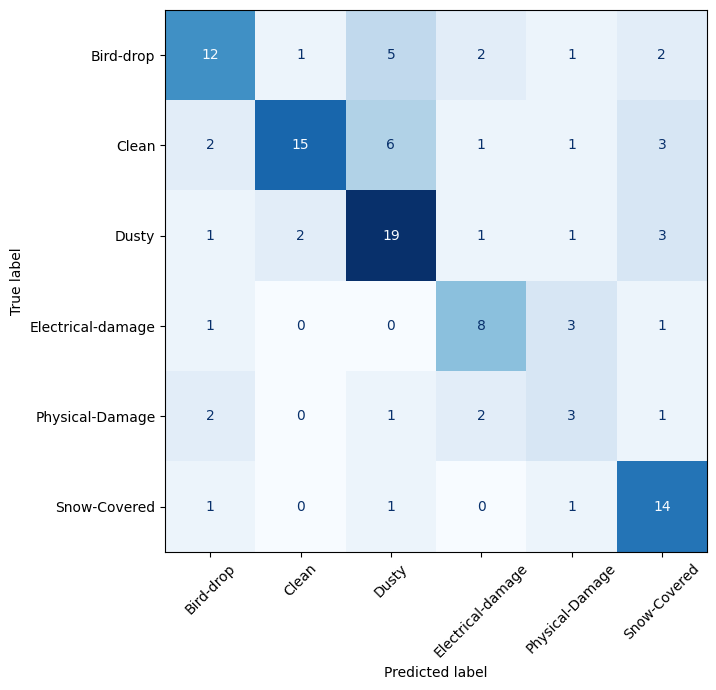

Reglas simples
                   precision    recall  f1-score   support

        Bird-drop       0.43      0.52      0.47        23
            Clean       0.00      0.00      0.00        28
            Dusty       0.46      0.67      0.55        27
Electrical-damage       0.38      0.38      0.38        13
  Physical-Damage       0.22      0.56      0.31         9
     Snow-Covered       0.64      0.53      0.58        17

         accuracy                           0.42       117
        macro avg       0.36      0.44      0.38       117
     weighted avg       0.34      0.42      0.37       117



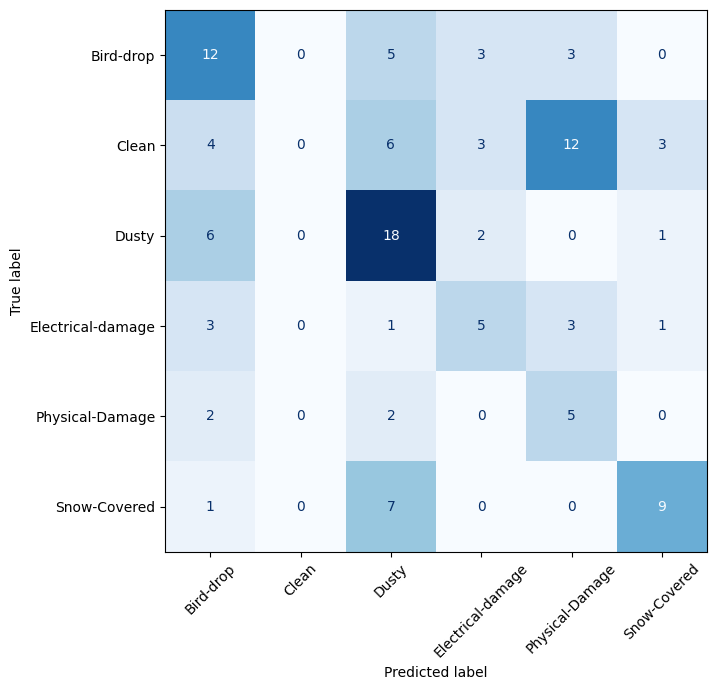

Daño etiquetado como eléctrico/físico predicho Clean: 0
Inferencia por lotes (incluye lectura): 24.24 ms/imagen; no incluye LLM ni notificaciones.


In [ ]:
dl_test=DataLoader(PanelesDataset(partes['test'],tf_eval),batch_size=64,shuffle=False,num_workers=0)
if DISP=='cuda':torch.cuda.synchronize()
t0=time.perf_counter();yt,pt=inferir_loader(modelo,dl_test)
if DISP=='cuda':torch.cuda.synchronize()
segundos=time.perf_counter()-t0
pred=pt.argmax(1)
Xte=np.array([caracteristicas(p) for p in partes['test'].ruta]);pred_base=baseline.predict(Xte)
RESULTADOS={'EfficientNet-B0':metricas(yt,pred),'Reglas simples':metricas(yt,pred_base)}
comparacion=pd.DataFrame(RESULTADOS).T;display(comparacion);comparacion.to_csv(OUT/'comparacion_prueba.csv')
for nombre,yp in [('EfficientNet-B0',pred),('Reglas simples',pred_base)]:
    reporte=classification_report(yt,yp,labels=LABELS,target_names=CLASES,output_dict=True,zero_division=0)
    pd.DataFrame(reporte).T.to_csv(OUT/f'metricas_{nombre}.csv')
    print(nombre);print(classification_report(yt,yp,labels=LABELS,target_names=CLASES,zero_division=0))
    fig,ax=plt.subplots(figsize=(9,7));ConfusionMatrixDisplay(confusion_matrix(yt,yp,labels=LABELS),display_labels=CLASES).plot(ax=ax,cmap='Blues',xticks_rotation=45,colorbar=False)
    plt.tight_layout();plt.savefig(OUT/f'matriz_{nombre}.png');plt.show()
criticos=np.isin(yt,[CLASE_A_ID['Electrical-damage'],CLASE_A_ID['Physical-Damage']]) & (pred==CLASE_A_ID['Clean'])
print('Daño etiquetado como eléctrico/físico predicho Clean:',int(criticos.sum()))
print('Inferencia por lotes (incluye lectura):',round(1000*segundos/len(yt),2),'ms/imagen; no incluye LLM ni notificaciones.')
registro=partes['test'][['ruta_relativa','clase','grupo']].copy()
registro['prediccion']=[CLASES[i] for i in pred];registro['confianza']=pt.max(1)
registro['baja_confianza']=pt.max(1)<UMBRAL_REVISION
registro['revision_humana']=registro.baja_confianza|registro.prediccion.isin(['Electrical-damage','Physical-Damage'])
for k,c in enumerate(CLASES):registro['p_'+c]=pt[:,k]
registro.to_csv(OUT/'predicciones_prueba.csv',index=False)


## 8. Revisión de las imágenes mal clasificadas

Los errores se examinan mediante ejemplos que muestran la fotografía, la etiqueta de referencia y la predicción del modelo. Esta revisión permite relacionar las métricas con casos concretos y reconocer condiciones visuales que dificultan la clasificación.

Los ejemplos se utilizan para interpretar los resultados y formular propuestas de trabajo futuro. No se emplean para ajustar el modelo sobre el mismo conjunto utilizado en la evaluación final.


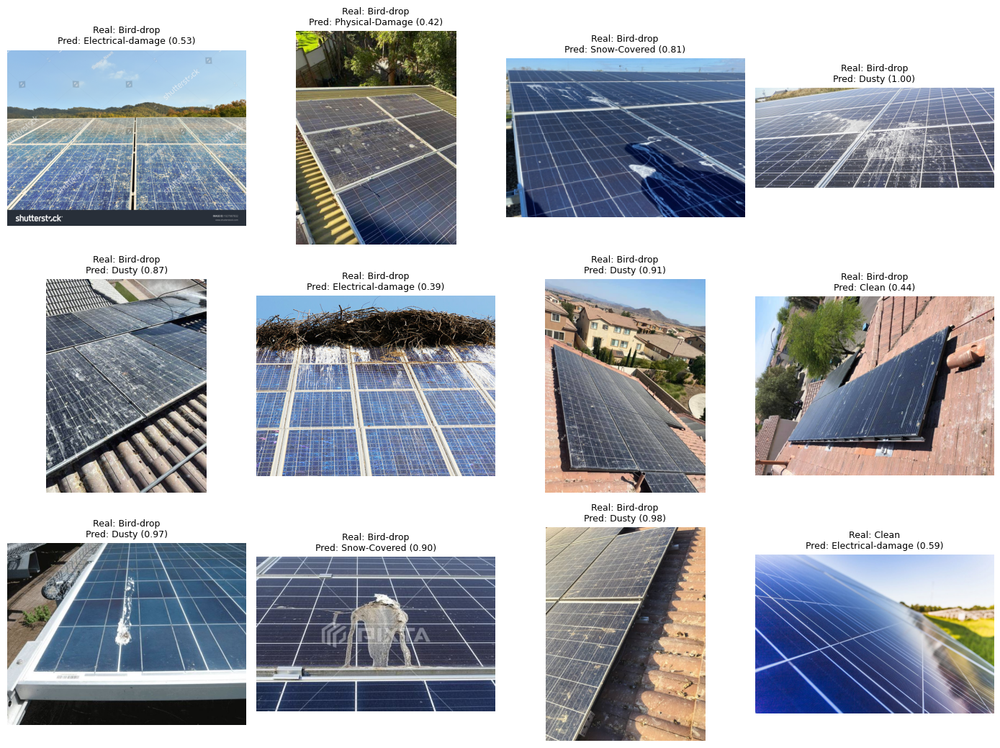

In [ ]:
errores=np.flatnonzero(pred!=yt)[:12]
if len(errores):
    fig,axs=plt.subplots((len(errores)+3)//4,4,figsize=(14,3.5*((len(errores)+3)//4)),squeeze=False)
    for ax in axs.flat:ax.axis('off')
    for ax,i in zip(axs.flat,errores):
        ax.imshow(abrir_rgb(partes['test'].iloc[i].ruta));ax.set_title(f'Real: {CLASES[yt[i]]}\nPred: {CLASES[pred[i]]} ({pt[i].max():.2f})',fontsize=9)
    plt.tight_layout();plt.savefig(OUT/'errores.png');plt.show()
else:print('No hay errores en esta prueba; esto no demuestra desempeño perfecto fuera del dataset.')


## 9. Efecto de los errores sobre el mantenimiento

Una confusión entre clases no siempre modifica la acción recomendada. Por ejemplo, clasificar polvo como excrementos de aves sigue orientando hacia una limpieza, mientras que clasificar un daño como suciedad puede omitir una inspección técnica. Para distinguir estas consecuencias, se relacionan las clases con las siguientes acciones:

| Condición visual | Acción orientativa |
|---|---|
| Clean | Seguimiento y registro |
| Dusty / Bird-drop | Limpieza e inspección visual |
| Electrical-damage / Physical-Damage | Inspección técnica prioritaria |
| Snow-Covered | Evaluación operacional por nieve |

El análisis contabiliza tanto los daños que no generan una recomendación técnica como aquellos que quedarían sin derivación humana al aplicar la política de confianza. Estos resultados describen consecuencias potenciales de las predicciones; no representan incidentes observados ni una estimación de costos de mantenimiento.


In [ ]:
ACCIONES={
    'Bird-drop':'Limpieza e inspección visual',
    'Clean':'Seguimiento y registro',
    'Dusty':'Limpieza e inspección visual',
    'Electrical-damage':'Inspección técnica prioritaria',
    'Physical-Damage':'Inspección técnica prioritaria',
    'Snow-Covered':'Evaluación operacional por nieve'}
DANOS={'Electrical-damage','Physical-Damage'}
ORDEN_ACCIONES=list(dict.fromkeys(ACCIONES.values()))

def analizar_mantenimiento(y_real, y_pred, probabilidades, inventario, umbral=0.70):
    y_real=np.asarray(y_real,dtype=int);y_pred=np.asarray(y_pred,dtype=int)
    probabilidades=np.asarray(probabilidades,dtype=float)
    assert probabilidades.shape==(len(y_real),len(CLASES))
    assert len(inventario)==len(y_real)==len(y_pred)
    assert np.isfinite(probabilidades).all()
    assert (probabilidades>=0).all() and (probabilidades<=1).all()
    assert np.allclose(probabilidades.sum(1),1,atol=1e-5)
    assert np.array_equal(y_pred,probabilidades.argmax(1))
    reales=np.array([CLASES[i] for i in y_real]);predichas=np.array([CLASES[i] for i in y_pred])
    assert np.array_equal(inventario.clase.to_numpy(),reales),'El orden de prueba no coincide'
    tabla=inventario[['ruta','ruta_relativa','clase','grupo']].copy().reset_index(drop=True)
    tabla['prediccion']=predichas;tabla['confianza']=probabilidades.max(1)
    tabla['accion_real']=tabla.clase.map(ACCIONES);tabla['accion_predicha']=tabla.prediccion.map(ACCIONES)
    tabla['error_clase']=reales!=predichas
    tabla['error_accion']=tabla.accion_real!=tabla.accion_predicha
    tabla['dano_real']=tabla.clase.isin(DANOS);tabla['predice_dano']=tabla.prediccion.isin(DANOS)
    tabla['baja_confianza']=tabla.confianza<umbral
    tabla['revision_humana']=tabla.baja_confianza|tabla.predice_dano
    tabla['dano_sin_recomendar_tecnico']=tabla.dano_real&~tabla.predice_dano
    tabla['dano_sin_derivacion']=tabla.dano_real&~tabla.revision_humana
    tabla['error_alta_confianza']=tabla.error_clase&~tabla.baja_confianza
    tabla['prioridad_analisis']=np.select([
        tabla.dano_sin_derivacion,tabla.dano_sin_recomendar_tecnico,
        tabla.error_accion,tabla.error_clase],[0,1,2,3],default=4)
    sin_revision=~tabla.revision_humana
    resumen={
        'n_prueba':len(tabla),'errores_clase':int(tabla.error_clase.sum()),
        'errores_accion':int(tabla.error_accion.sum()),
        'danos_reales':int(tabla.dano_real.sum()),
        'dano_predicho_clean':int((tabla.dano_real&tabla.prediccion.eq('Clean')).sum()),
        'dano_sin_recomendar_tecnico':int(tabla.dano_sin_recomendar_tecnico.sum()),
        'dano_sin_derivacion_humana':int(tabla.dano_sin_derivacion.sum()),
        'errores_alta_confianza':int(tabla.error_alta_confianza.sum()),
        'derivaciones_revision_humana':int(tabla.revision_humana.sum()),
        'proporcion_revision':float(tabla.revision_humana.mean()),
        'n_sin_revision':int(sin_revision.sum()),
        'accuracy_sin_revision':float((~tabla.loc[sin_revision,'error_clase']).mean()) if sin_revision.any() else None}
    return tabla,resumen


EfficientNet-B0


,clase,prediccion,confianza,accion_real,accion_predicha,revision_humana
97,Physical-Damage,Bird-drop,0.855707,Inspección técnica prioritaria,Limpieza e inspección visual,False
90,Electrical-damage,Snow-Covered,0.772935,Inspección técnica prioritaria,Evaluación operacional por nieve,False
93,Physical-Damage,Snow-Covered,0.607618,Inspección técnica prioritaria,Evaluación operacional por nieve,True
89,Electrical-damage,Bird-drop,0.515327,Inspección técnica prioritaria,Limpieza e inspección visual,True
91,Physical-Damage,Bird-drop,0.442603,Inspección técnica prioritaria,Limpieza e inspección visual,True
96,Physical-Damage,Dusty,0.405174,Inspección técnica prioritaria,Limpieza e inspección visual,True
24,Clean,Dusty,0.998915,Seguimiento y registro,Limpieza e inspección visual,False
107,Snow-Covered,Dusty,0.995171,Evaluación operacional por nieve,Limpieza e inspección visual,False
43,Clean,Physical-Damage,0.978140,Seguimiento y registro,Inspección técnica prioritaria,True
53,Dusty,Clean,0.956497,Limpieza e inspección visual,Seguimiento y registro,False


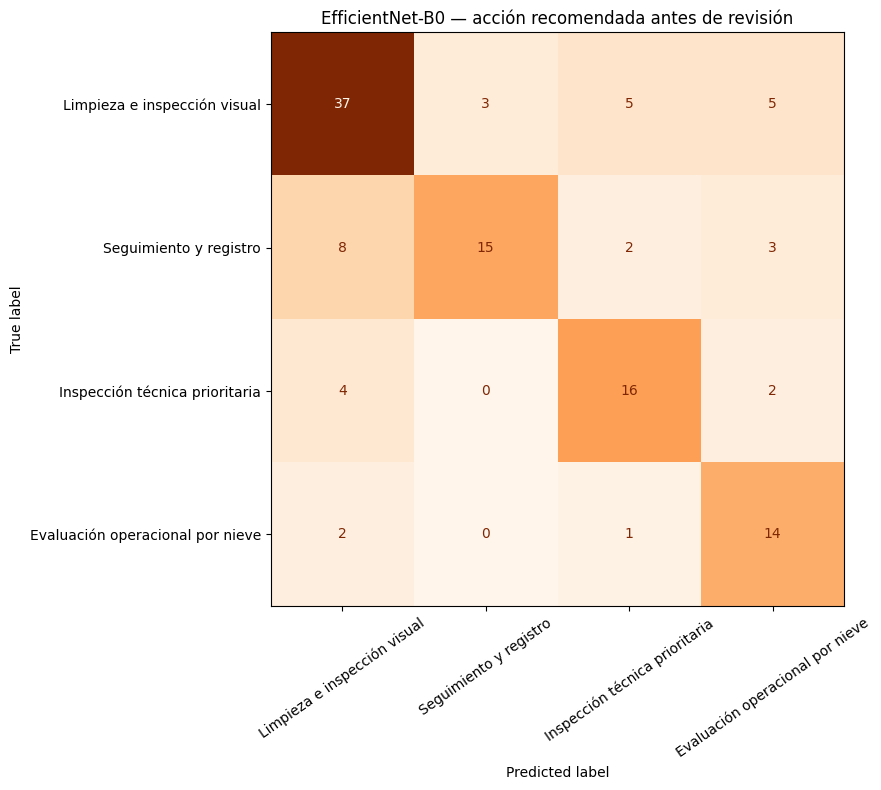

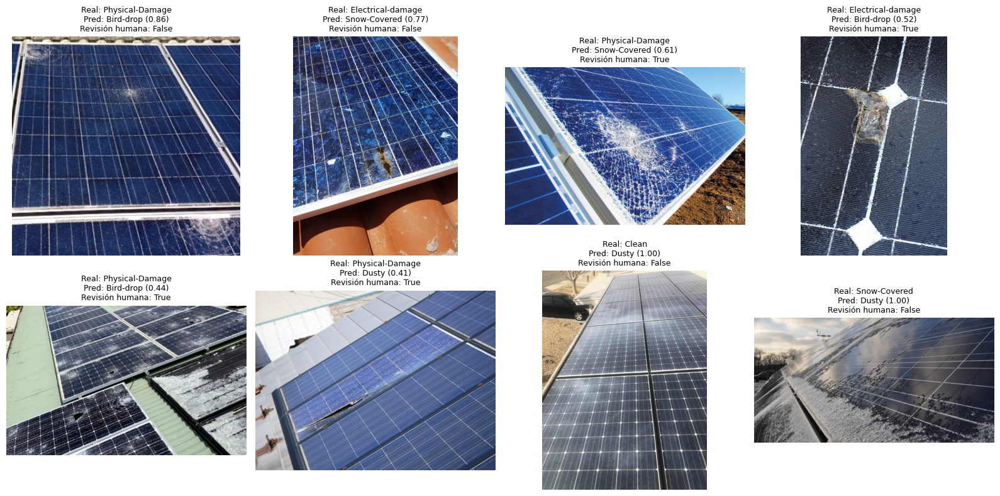

Reglas simples


,clase,prediccion,confianza,accion_real,accion_predicha,revision_humana
80,Electrical-damage,Snow-Covered,0.520239,Inspección técnica prioritaria,Evaluación operacional por nieve,True
87,Electrical-damage,Dusty,0.482743,Inspección técnica prioritaria,Limpieza e inspección visual,True
92,Physical-Damage,Dusty,0.482743,Inspección técnica prioritaria,Limpieza e inspección visual,True
96,Physical-Damage,Dusty,0.482743,Inspección técnica prioritaria,Limpieza e inspección visual,True
84,Electrical-damage,Bird-drop,0.429018,Inspección técnica prioritaria,Limpieza e inspección visual,True
85,Electrical-damage,Bird-drop,0.429018,Inspección técnica prioritaria,Limpieza e inspección visual,True
86,Electrical-damage,Bird-drop,0.429018,Inspección técnica prioritaria,Limpieza e inspección visual,True
91,Physical-Damage,Bird-drop,0.429018,Inspección técnica prioritaria,Limpieza e inspección visual,True
95,Physical-Damage,Bird-drop,0.429018,Inspección técnica prioritaria,Limpieza e inspección visual,True
23,Clean,Snow-Covered,0.683951,Seguimiento y registro,Evaluación operacional por nieve,True


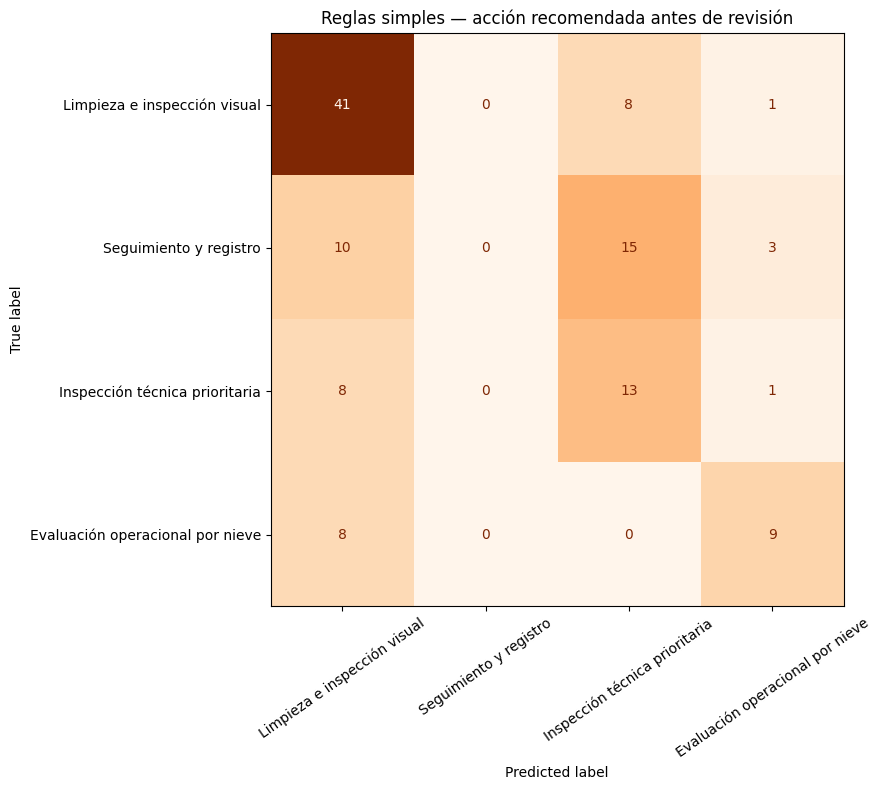

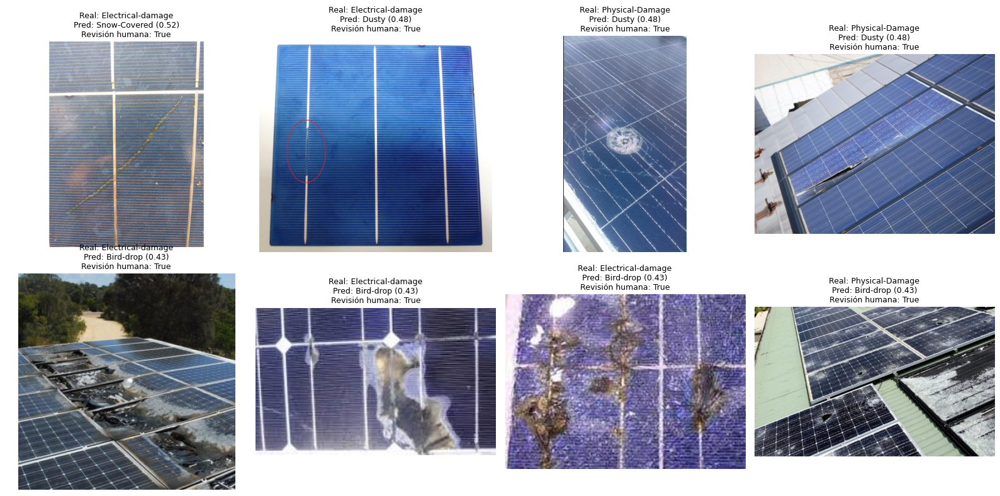

,n_prueba,errores_clase,errores_accion,danos_reales,dano_predicho_clean,dano_sin_recomendar_tecnico,dano_sin_derivacion_humana,errores_alta_confianza,derivaciones_revision_humana,proporcion_revision,n_sin_revision,accuracy_sin_revision
EfficientNet-B0,117.0,46.0,35.0,22.0,0.0,6.0,2.0,25.0,48.0,0.410256,69.0,0.695652
Reglas simples,117.0,68.0,54.0,22.0,0.0,9.0,0.0,0.0,111.0,0.948718,6.0,1.000000


Los puntajes de la red y del árbol no están calibrados: una confianza igual no implica igual fiabilidad.
La accuracy sin revisión describe un subconjunto: no reemplaza las métricas sobre toda la prueba.


In [ ]:
# Verificar que los dos métodos usan exactamente el mismo orden de prueba.
y_esperado=partes['test'].clase.map(CLASE_A_ID).to_numpy()
np.testing.assert_array_equal(yt,y_esperado)
# predict_proba puede ordenar columnas por clases_: se alinean explícitamente.
pb=np.zeros((len(yt),len(CLASES)),dtype=float)
pb[:,baseline.classes_.astype(int)]=baseline.predict_proba(Xte)
operacion={};resumenes_operacion={}
for nombre,yp,pp in [('EfficientNet-B0',pred,pt),('Reglas simples',pred_base,pb)]:
    tabla,resumen=analizar_mantenimiento(yt,yp,pp,partes['test'],UMBRAL_REVISION)
    operacion[nombre]=tabla;resumenes_operacion[nombre]=resumen
    tabla.to_csv(OUT/f'analisis_mantenimiento_{nombre}.csv',index=False)
    fallos=tabla[tabla.error_clase].sort_values(['prioridad_analisis','confianza'],ascending=[True,False])
    fallos.to_csv(OUT/f'errores_priorizados_{nombre}.csv',index=False)
    print(nombre)
    display(fallos[['clase','prediccion','confianza','accion_real','accion_predicha','revision_humana']].head(12))
    # Matriz por acción: filas reales y columnas predichas, antes de revisión humana.
    cm_acc=confusion_matrix(tabla.accion_real,tabla.accion_predicha,labels=ORDEN_ACCIONES)
    fig,ax=plt.subplots(figsize=(10,8))
    ConfusionMatrixDisplay(cm_acc,display_labels=ORDEN_ACCIONES).plot(ax=ax,cmap='Oranges',xticks_rotation=35,colorbar=False)
    ax.set_title(nombre+' — acción recomendada antes de revisión')
    plt.tight_layout();plt.savefig(OUT/f'matriz_acciones_{nombre}.png',dpi=140);plt.show()
    # Hasta ocho ejemplos de error por método, priorizando consecuencias operacionales.
    muestra=fallos.head(8)
    if len(muestra):
        fig,axs=plt.subplots((len(muestra)+3)//4,4,figsize=(16,4*((len(muestra)+3)//4)),squeeze=False)
        for ax in axs.flat:ax.axis('off')
        for ax,(_,r) in zip(axs.flat,muestra.iterrows()):
            ax.imshow(abrir_rgb(r.ruta))
            ax.set_title(f"Real: {r.clase}\nPred: {r.prediccion} ({r.confianza:.2f})\nRevisión humana: {r.revision_humana}",fontsize=9)
        plt.tight_layout();plt.savefig(OUT/f'errores_operacionales_{nombre}.png',dpi=140);plt.show()
resumen_operacional=pd.DataFrame(resumenes_operacion).T
display(resumen_operacional)
resumen_operacional.to_csv(OUT/'resumen_operacional.csv')
print('Los puntajes de la red y del árbol no están calibrados: una confianza igual no implica igual fiabilidad.')
print('La accuracy sin revisión describe un subconjunto: no reemplaza las métricas sobre toda la prueba.')


## 10. Síntesis de la evaluación

La síntesis reúne la selección realizada con validación y el desempeño obtenido posteriormente en prueba. Se compara el resultado de EfficientNet-B0 con las reglas visuales, se identifica la clase de menor recall y se examina la proporción de casos que requeriría revisión humana.

Las conclusiones se calculan a partir de los resultados de la ejecución. Su interpretación considera el número de ejemplos por clase y las consecuencias operacionales de los errores. La aplicación en una planta requerirá una evaluación adicional con imágenes independientes y representativas de sus condiciones de operación.


In [ ]:
from IPython.display import Markdown
seleccionado_validacion=comparacion_val.macro_f1.idxmax()
reporte_eff=classification_report(yt,pred,labels=LABELS,target_names=CLASES,output_dict=True,zero_division=0)
clase_debil=min(CLASES,key=lambda c:reporte_eff[c]['recall'])
res=resumenes_operacion['EfficientNet-B0']
conteo_test=partes['test'].clase.value_counts()
correctos_debil=int(((yt==CLASE_A_ID[clase_debil])&(pred==yt)).sum())
diferencia=100*(RESULTADOS['EfficientNet-B0']['macro_f1']-RESULTADOS['Reglas simples']['macro_f1'])
texto=f"""# SolarScan — resultados de entrenamiento y evaluación

Se utilizaron {len(partes['train'])} imágenes de entrenamiento, {len(partes['val'])} de validación y {len(partes['test'])} de prueba, manteniendo juntos los grupos similares detectados. Los conteos pertenecen a esta ejecución.

La mejor época de EfficientNet-B0 según macro-F1 de validación fue la {MEJOR_EPOCA}. El árbol simple utiliza profundidad {profundidad}, elegida con validación. El método preferido por macro-F1 de validación es **{seleccionado_validacion}**. No se seleccionó usando prueba.

En prueba, EfficientNet-B0 obtuvo accuracy {RESULTADOS['EfficientNet-B0']['accuracy']:.1%}, accuracy balanceada {RESULTADOS['EfficientNet-B0']['accuracy_balanceada']:.1%} y macro-F1 {RESULTADOS['EfficientNet-B0']['macro_f1']:.1%}. Las reglas simples obtuvieron accuracy {RESULTADOS['Reglas simples']['accuracy']:.1%} y macro-F1 {RESULTADOS['Reglas simples']['macro_f1']:.1%}. La diferencia de macro-F1 (EfficientNet menos reglas) fue {diferencia:+.1f} puntos porcentuales; no se realizó una prueba de significancia estadística.

La clase con menor recall de EfficientNet fue **{clase_debil}**: {correctos_debil} aciertos de {int(conteo_test[clase_debil])} imágenes ({reporte_eff[clase_debil]['recall']:.1%}). El tamaño por clase debe acompañar el porcentaje.

De {res['danos_reales']} imágenes etiquetadas como daño eléctrico o físico, {res['dano_predicho_clean']} se predijeron Clean y {res['dano_sin_recomendar_tecnico']} se predijeron como una clase que no recomienda inspección técnica. Aplicando la política de revisión existente, {res['dano_sin_derivacion_humana']} de esos daños quedarían sin derivación humana. Estas son consecuencias simuladas de las predicciones, no incidentes reales.

La política deriva {res['derivaciones_revision_humana']} de {len(yt)} imágenes a revisión ({res['proporcion_revision']:.1%}). Hay {res['errores_alta_confianza']} errores de clase con puntaje igual o superior a {UMBRAL_REVISION:.2f}: un puntaje alto no garantiza acierto.

El modelo es un prototipo de apoyo. Las etiquetas son visuales y la fotografía no confirma una falla eléctrica. La agrupación por similitud reduce duplicados entre conjuntos, pero no demuestra independencia por planta. No se midieron pérdidas energéticas ni costos. El tiempo de inferencia no equivale al tiempo completo recepción-recomendación.

No se modifican hiperparámetros con esta prueba. Las mejoras futuras requieren una evaluación nueva e independiente, especialmente para las clases con bajo recall.
"""
(OUT/'conclusiones_paso4.md').write_text(texto,encoding='utf-8');display(Markdown(texto))
seleccion={'criterio':'macro_f1_validacion','metodo_preferido':seleccionado_validacion,
           'epoca_efficientnet':int(MEJOR_EPOCA),'profundidad_reglas':int(profundidad),
           'umbral_revision':float(UMBRAL_REVISION),'costo_20_a_1':False,
           'nota':'Se exporta EfficientNet como candidato; la selección por validación queda registrada aparte.'}
(OUT/'seleccion_validacion.json').write_text(json.dumps(seleccion,indent=2,ensure_ascii=False))
# Verificación de evidencia del paso 4.
requeridos=['historia.csv','reglas_baseline.txt','comparacion_validacion.csv','comparacion_prueba.csv',
 'metricas_EfficientNet-B0.csv','metricas_Reglas simples.csv','predicciones_prueba.csv',
 'resumen_operacional.csv','conclusiones_paso4.md','seleccion_validacion.json']
assert all((OUT/f).is_file() for f in requeridos),'Falta ejecutar una sección previa'
print('Evidencias del paso 4 completas. Ejecuta ahora la exportación actualizada.')


# SolarScan — resultados de entrenamiento y evaluación

Se utilizaron 552 imágenes de entrenamiento, 118 de validación y 117 de prueba, manteniendo juntos los grupos similares detectados. Los conteos pertenecen a esta ejecución.

La mejor época de EfficientNet-B0 según macro-F1 de validación fue la 9. El árbol simple utiliza profundidad 3, elegida con validación. El método preferido por macro-F1 de validación es **EfficientNet-B0**. No se seleccionó usando prueba.

En prueba, EfficientNet-B0 obtuvo accuracy 60.7%, accuracy balanceada 58.9% y macro-F1 57.6%. Las reglas simples obtuvieron accuracy 41.9% y macro-F1 38.2%. La diferencia de macro-F1 (EfficientNet menos reglas) fue +19.4 puntos porcentuales; no se realizó una prueba de significancia estadística.

La clase con menor recall de EfficientNet fue **Physical-Damage**: 3 aciertos de 9 imágenes (33.3%). El tamaño por clase debe acompañar el porcentaje.

De 22 imágenes etiquetadas como daño eléctrico o físico, 0 se predijeron Clean y 6 se predijeron como una clase que no recomienda inspección técnica. Aplicando la política de revisión existente, 2 de esos daños quedarían sin derivación humana. Estas son consecuencias simuladas de las predicciones, no incidentes reales.

La política deriva 48 de 117 imágenes a revisión (41.0%). Hay 25 errores de clase con puntaje igual o superior a 0.70: un puntaje alto no garantiza acierto.

El modelo es un prototipo de apoyo. Las etiquetas son visuales y la fotografía no confirma una falla eléctrica. La agrupación por similitud reduce duplicados entre conjuntos, pero no demuestra independencia por planta. No se midieron pérdidas energéticas ni costos. El tiempo de inferencia no equivale al tiempo completo recepción-recomendación.

No se modifican hiperparámetros con esta prueba. Las mejoras futuras requieren una evaluación nueva e independiente, especialmente para las clases con bajo recall.


Evidencias del paso 4 completas. Ejecuta ahora la exportación actualizada.


## 11. Exportación del modelo

Para utilizar el clasificador fuera del entrenamiento, se guardan sus pesos, el orden de las clases, las transformaciones, el umbral de revisión y las métricas. Se registran también las versiones de las dependencias utilizadas.

La exportación se comprueba reconstruyendo el modelo en CPU y comparando sus probabilidades con las del modelo en memoria. Esta verificación permite detectar diferencias introducidas durante el guardado o la carga. El módulo resultante procesa imágenes nuevas sin descargar nuevamente el dataset.


In [ ]:
import importlib.metadata as metadata
EXPORT=OUT/'export';(EXPORT/'modelo').mkdir(parents=True,exist_ok=True)
torch.save(modelo.state_dict(),EXPORT/'modelo/efficientnet_b0_solar.pt')
versiones={p:metadata.version(p) for p in ['torch','torchvision','timm','numpy','pandas','Pillow','scipy','scikit-learn','kagglehub']}
config={**CONFIG_BASE,'clase_a_id':CLASE_A_ID,'umbral_revision':UMBRAL_REVISION,
 'confianza_calibrada':False,'preprocesamiento':'EXIF -> RGB -> ImageOps.pad bilinear gris 128 -> tensor -> Normalize',
 'dataset':'pythonafroz/solar-panel-images','data_root':str(DATA_ROOT),'semilla':SEMILLA,'mejor_epoca':MEJOR_EPOCA,
 'metricas_validacion':metricas_eff_val,'metricas_prueba':RESULTADOS['EfficientNet-B0'],
 'matriz_confusion':confusion_matrix(yt,pred,labels=LABELS).tolist(),'comparacion_prueba':RESULTADOS,
 'seleccion_validacion':seleccion,'evaluacion_operacional':resumenes_operacion,
 'versiones':versiones,'limite':'Evaluación interna; pHash no garantiza independencia por planta/panel.',
 'politica_revision':'Baja confianza o clase Electrical-damage/Physical-Damage requiere revisión humana.'}
(EXPORT/'modelo/config.json').write_text(json.dumps(config,indent=2,ensure_ascii=False))
(EXPORT/'inferencia_solar.py').write_text(INFERENCIA_SRC,encoding='utf-8')
(EXPORT/'requirements.txt').write_text('\n'.join(f'{p}=={v}' for p,v in versiones.items()))
recargado,cfg,tf=cargar_modelo(EXPORT/'modelo','cpu')
ruta=partes['val'].iloc[0].ruta
original=predecir(ruta,modelo,config,tf_eval,DISP);cargado=predecir(ruta,recargado,cfg,tf,'cpu')
np.testing.assert_allclose(list(original['probabilidades'].values()),list(cargado['probabilidades'].values()),rtol=1e-3,atol=1e-4)
print('Exportación verificada: predicciones equivalentes tras recarga.');print(json.dumps(cargado,indent=2,ensure_ascii=False))
# La descarga incluye registros, reglas, gráficos y pesos; evita incluir imágenes originales.
from google.colab import files
archivo=shutil.make_archive(str(OUT)+'_entrenamiento','zip',OUT)
files.download(archivo)


Exportación verificada: predicciones equivalentes tras recarga.
{
  "clase": "Bird-drop",
  "confianza": 0.9181756377220154,
  "baja_confianza": false,
  "revision_humana": false,
  "probabilidades": {
    "Bird-drop": 0.9181756377220154,
    "Clean": 0.024883326143026352,
    "Dusty": 0.028751365840435028,
    "Electrical-damage": 0.000731848762370646,
    "Physical-Damage": 0.027287298813462257,
    "Snow-Covered": 0.00017061043763533235
  },
  "nota": "Puntaje softmax no calibrado; no confirma una falla eléctrica."
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Limitaciones del estudio

El conjunto presenta diferencias en la cantidad de imágenes por clase, posibles escenas similares y etiquetas cuya interpretación puede ser discutible. Además, cada fotografía tiene una sola etiqueta, aunque en un panel real puedan coexistir polvo, daños u otras condiciones.

Estas características limitan el alcance de las métricas obtenidas. La evaluación describe el desempeño dentro del dataset y no permite afirmar el mismo resultado en otras plantas, cámaras o condiciones de iluminación. Tampoco se dispone de mediciones eléctricas que permitan confirmar fallas o estimar su efecto sobre la generación.

Por estas razones, SolarScan se plantea como una herramienta de apoyo a la inspección y mantiene la participación del encargado de mantenimiento en la decisión final.

**Referencias técnicas**

- [Transferencia de aprendizaje con timm](https://huggingface.co/docs/timm/quickstart).
- [Guardado y carga de modelos en PyTorch](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html).
- [Árboles de decisión en scikit-learn](https://scikit-learn.org/stable/modules/tree.html).


## 13. Desarrollo del servicio de inferencia

La preparación del servicio permite separar el entrenamiento del uso posterior del modelo. El componente recibe una imagen, aplica el procesamiento definido y devuelve una clasificación estructurada, de modo que pueda incorporarse a un flujo de inspección.

Las secciones siguientes presentan la implementación y las comprobaciones previstas para su ejecución local. La conexión con n8n se desarrollará posteriormente, una vez verificado el servicio con los archivos del modelo exportado.


## 14. Recepción de imágenes y respuesta del servicio

El servicio dispone de una operación `POST /predict`, que recibe una imagen mediante el campo `file`. La respuesta incluye un identificador de inspección, fecha UTC, versión del modelo, clase predicha, confianza, probabilidades y necesidad de revisión humana. La operación `GET /health` informa si el modelo está disponible.

La entrada se valida antes de realizar la predicción. Se admiten imágenes estáticas en formatos JPEG, PNG, WEBP y BMP, con un máximo de 15 MiB y 40 millones de píxeles. Se comprueba que el contenido pueda decodificarse y se diferencian los errores de archivo de los fallos del servicio. Esta validación no determina si la fotografía corresponde efectivamente a un panel solar.

El servicio reutiliza los pesos y el módulo de inferencia exportados. La ubicación de estos archivos se define mediante `EXPORT_ORIGEN` cuando se trabaja con una exportación previa. No es necesario repetir el entrenamiento para preparar el servicio si se dispone de esos archivos.


In [ ]:
%pip -q install "fastapi>=0.115,<1" "uvicorn>=0.30,<1" "httpx>=0.27,<1" python-multipart pytest

In [ ]:
ARCHIVOS_SERVICIO = {'api_solar.py': '"""Servicio local de inferencia de SolarScan; no conecta con n8n."""\nimport hashlib\nimport io\nimport logging\nimport math\nimport os\nimport tempfile\nimport threading\nimport time\nimport uuid\nfrom contextlib import asynccontextmanager\nfrom datetime import datetime, timezone\nfrom pathlib import Path\nfrom typing import Annotated, Literal\n\nfrom fastapi import FastAPI, File, HTTPException, Request, UploadFile\nfrom fastapi.responses import JSONResponse\nfrom pydantic import BaseModel, Field\nfrom PIL import Image, UnidentifiedImageError\nfrom starlette.concurrency import run_in_threadpool\n\nCLASES = [\'Bird-drop\', \'Clean\', \'Dusty\', \'Electrical-damage\', \'Physical-Damage\', \'Snow-Covered\']\nMAX_BYTES = 15 * 1024 * 1024\nMAX_PIXELS = 40_000_000\nFORMATOS = {\'JPEG\', \'PNG\', \'WEBP\', \'BMP\'}\nlogger = logging.getLogger(\'solarscan\')\n\nclass Resultado(BaseModel):\n    inspeccion_id: str\n    fecha_utc: str\n    modelo_version: str\n    clase: Literal[\'Bird-drop\',\'Clean\',\'Dusty\',\'Electrical-damage\',\'Physical-Damage\',\'Snow-Covered\']\n    confianza: float = Field(ge=0, le=1)\n    baja_confianza: bool\n    revision_humana: bool\n    probabilidades: dict[str, float]\n    nota: str\n    tiempo_servicio_ms: float = Field(ge=0)\n\ndef validar_imagen(data: bytes, max_bytes=MAX_BYTES, max_pixels=MAX_PIXELS):\n    if not data:\n        raise HTTPException(400, \'El archivo está vacío.\')\n    if len(data) > max_bytes:\n        raise HTTPException(413, \'El archivo supera el límite de tamaño.\')\n    try:\n        with Image.open(io.BytesIO(data)) as im:\n            if im.format not in FORMATOS:\n                raise HTTPException(415, \'Formato no admitido. Utilice JPEG, PNG, WEBP o BMP.\')\n            if getattr(im, \'n_frames\', 1) != 1:\n                raise HTTPException(415, \'Se requiere una imagen estática de un solo fotograma.\')\n            if im.width * im.height > max_pixels:\n                raise HTTPException(413, \'La resolución supera el límite permitido.\')\n            im.verify()\n        with Image.open(io.BytesIO(data)) as im:\n            im.load()\n    except HTTPException:\n        raise\n    except Image.DecompressionBombError:\n        raise HTTPException(413, \'La resolución supera el límite permitido.\')\n    except (UnidentifiedImageError, OSError, ValueError, SyntaxError):\n        raise HTTPException(422, \'No se pudo decodificar una imagen válida.\')\n\nclass PredictorSolar:\n    def __init__(self, model_dir):\n        # Se importa al iniciar el servicio, no durante las pruebas con dobles.\n        from inferencia_solar import cargar_modelo, predecir\n        model_dir = Path(model_dir)\n        self.modelo, self.config, self.tf = cargar_modelo(model_dir, \'cpu\')\n        if self.config[\'clases\'] != CLASES:\n            raise ValueError(\'El orden de clases no corresponde al contrato de SolarScan.\')\n        if not 0 <= self.config[\'umbral_revision\'] <= 1:\n            raise ValueError(\'Umbral inválido.\')\n        self.predecir = predecir\n        h = hashlib.sha256()\n        for file in [model_dir/\'efficientnet_b0_solar.pt\', model_dir/\'config.json\']:\n            with file.open(\'rb\') as f:\n                for chunk in iter(lambda: f.read(1024*1024), b\'\'):\n                    h.update(chunk)\n        self.version = h.hexdigest()[:16]\n        self.lock = threading.Lock()\n\n    def __call__(self, data):\n        # Conserva los bytes originales y el procesamiento de inferencia existente.\n        # El archivo temporal se elimina también si la predicción falla.\n        with tempfile.TemporaryDirectory(prefix=\'solarscan_\') as temp:\n            path = Path(temp)/\'entrada.img\'\n            path.write_bytes(data)\n            with self.lock:\n                return self.predecir(path, self.modelo, self.config, self.tf, \'cpu\')\n\ndef create_app(model_dir=None, predictor=None, max_bytes=MAX_BYTES, max_pixels=MAX_PIXELS):\n    @asynccontextmanager\n    async def lifespan(app):\n        app.state.predictor = None\n        try:\n            app.state.predictor = predictor if predictor is not None else await run_in_threadpool(\n                PredictorSolar, model_dir or Path(__file__).parent/\'modelo\')\n        except Exception:\n            logger.exception(\'No fue posible cargar el modelo.\')\n        yield\n        app.state.predictor = None\n\n    app = FastAPI(title=\'SolarScan\', version=\'1.0.0\', lifespan=lifespan,\n                  description=\'Clasificación visual de paneles solares para apoyo a O&M.\')\n\n    @app.middleware(\'http\')\n    async def identificar(request: Request, call_next):\n        request.state.inspeccion_id = str(uuid.uuid4())\n        response = await call_next(request)\n        response.headers[\'X-Inspection-ID\'] = request.state.inspeccion_id\n        return response\n\n    @app.exception_handler(HTTPException)\n    async def error_controlado(request: Request, exc: HTTPException):\n        return JSONResponse(status_code=exc.status_code, content={\n            \'inspeccion_id\': request.state.inspeccion_id, \'error\': exc.detail})\n\n    @app.get(\'/health\')\n    def health():\n        ready = getattr(app.state, \'predictor\', None)\n        if ready is None:\n            raise HTTPException(503, \'El modelo no está disponible.\')\n        return {\'estado\': \'listo\', \'modelo_version\': ready.version}\n\n    @app.post(\'/predict\', response_model=Resultado)\n    async def predict(request: Request, file: Annotated[UploadFile, File()]):\n        start = time.perf_counter()\n        try:\n            data = await file.read(max_bytes + 1)\n        finally:\n            await file.close()\n        await run_in_threadpool(validar_imagen, data, max_bytes, max_pixels)\n        loaded = getattr(app.state, \'predictor\', None)\n        if loaded is None:\n            raise HTTPException(503, \'El modelo no está disponible.\')\n        try:\n            result = await run_in_threadpool(loaded, data)\n            probs = result[\'probabilidades\']\n            if set(probs) != set(CLASES) or not all(math.isfinite(v) and 0 <= v <= 1 for v in probs.values()):\n                raise ValueError(\'Probabilidades inválidas.\')\n            if abs(sum(probs.values()) - 1) > 1e-4:\n                raise ValueError(\'Probabilidades no normalizadas.\')\n            return Resultado(**result, inspeccion_id=request.state.inspeccion_id,\n                fecha_utc=datetime.now(timezone.utc).isoformat(), modelo_version=loaded.version,\n                tiempo_servicio_ms=round(1000*(time.perf_counter()-start), 3))\n        except Exception:\n            logger.exception(\'Error de inferencia. inspeccion_id=%s\', request.state.inspeccion_id)\n            raise HTTPException(500, \'No fue posible completar la predicción.\')\n    return app\n\napp = create_app(os.environ.get(\'SOLARSCAN_MODEL_DIR\'))\n', 'test_api.py': '"""Pruebas del contrato HTTP con un predictor simulado; no miden el modelo."""\nimport io\nfrom PIL import Image\nfrom fastapi.testclient import TestClient\nfrom api_solar import create_app, CLASES\n\nclass PredictorPrueba:\n    version=\'prueba-sin-pesos\'\n    def __call__(self,data):\n        return dict(clase=\'Clean\',confianza=.9,baja_confianza=False,revision_humana=False,\n            probabilidades={c:(.9 if c==\'Clean\' else .02) for c in CLASES},nota=\'Predicción simulada para prueba.\')\n\ndef imagen(formato=\'PNG\'):\n    out=io.BytesIO();Image.new(\'RGB\',(64,64),(20,40,60)).save(out,format=formato);return out.getvalue()\n\ndef test_success():\n    with TestClient(create_app(predictor=PredictorPrueba())) as c:\n        assert c.get(\'/health\').status_code==200\n        ids=[]\n        for fmt in [\'PNG\',\'JPEG\',\'BMP\',\'WEBP\']:\n            r=c.post(\'/predict\',files={\'file\':(\'imagen.bin\',imagen(fmt),\'application/octet-stream\')})\n            assert r.status_code==200,r.text\n            d=r.json();assert d[\'clase\']==\'Clean\';assert len(d[\'probabilidades\'])==6\n            assert r.headers[\'X-Inspection-ID\']==d[\'inspeccion_id\'];ids.append(d[\'inspeccion_id\'])\n        assert len(set(ids))==4\n\ndef test_bad_files():\n    with TestClient(create_app(predictor=PredictorPrueba(),max_bytes=1000)) as c:\n        assert c.post(\'/predict\',files={\'file\':(\'x\',b\'\')}).status_code==400\n        assert c.post(\'/predict\',files={\'file\':(\'x.jpg\',b\'no es imagen\')}).status_code==422\n        assert c.post(\'/predict\',files={\'file\':(\'x\',b\'x\'*1001)}).status_code==413\n        assert c.post(\'/predict\',files={\'file\':(\'x.gif\',imagen(\'GIF\'))}).status_code==415\n        assert c.post(\'/predict\').status_code==422\n    with TestClient(create_app(predictor=PredictorPrueba(),max_pixels=100)) as c:\n        assert c.post(\'/predict\',files={\'file\':(\'x\',imagen())}).status_code==413\n\ndef test_unavailable(tmp_path):\n    with TestClient(create_app(model_dir=tmp_path)) as c:\n        assert c.get(\'/health\').status_code==503\n        assert c.post(\'/predict\',files={\'file\':(\'x\',imagen())}).status_code==503\n\ndef test_internal_failure():\n    class Falla(PredictorPrueba):\n        def __call__(self,data):raise RuntimeError(\'detalle interno\')\n    with TestClient(create_app(predictor=Falla())) as c:\n        r=c.post(\'/predict\',files={\'file\':(\'x\',imagen())})\n        assert r.status_code==500 and \'detalle interno\' not in r.text\n', 'README.md': '# SolarScan: servicio de clasificación visual\n\n## Alcance\nServicio Python para clasificar una imagen en seis condiciones visuales. Devuelve clase, puntaje de confianza, probabilidades, indicador de revisión humana, UUID de inspección y versión del modelo. No incorpora n8n, un LLM, mensajería ni almacenamiento histórico. No confirma fallas eléctricas ni mide pérdidas de generación.\n\nEl notebook genera este directorio con los pesos reales de su sesión. El archivo .ipynb por sí solo contiene código y resultados visibles, no los pesos .pt. Conservar el ZIP del servicio descargado al finalizar la nueva sección.\n\n## Ejecución local\nRecomendado: Python 3.12, entorno virtual y CPU. Desde este directorio:\n\n```bash\npython -m venv .venv\n```\nActivar el entorno (`.venv\\Scripts\\activate` en Windows o `source .venv/bin/activate` en Linux/macOS).\n\n```bash\npython -m pip install -r requirements.txt\npython -m uvicorn api_solar:app --host 127.0.0.1 --port 8000\n```\nAbrir http://127.0.0.1:8000/docs para probar una imagen. `/health` confirma que el modelo se cargó. El servidor carga los pesos una sola vez al iniciar; no entrena ni descarga el dataset.\n\n## Contrato HTTP\n`POST /predict`, cuerpo `multipart/form-data`, campo **file**. Se aceptan JPEG, PNG, WEBP y BMP estáticos. Máximo 15 MiB y 40 millones de píxeles. Se inspecciona el contenido real; la extensión y el MIME declarados no bastan. La verificación comprueba el archivo, no que la foto sea realmente de un panel solar.\n\n```bash\ncurl -X POST http://127.0.0.1:8000/predict -F "file=@panel.jpg"\n```\n\nLa respuesta 200 contiene `inspeccion_id`, `fecha_utc`, `modelo_version`, `clase`, `confianza`, `baja_confianza`, `revision_humana`, `probabilidades`, `nota` y `tiempo_servicio_ms`. La fecha usa UTC. El UUID identifica cada solicitud, no un panel físico. El tiempo no incluye LLM, notificaciones ni todo el transporte HTTP.\n\n| Código | Significado |\n|---|---|\n| 400 | Archivo vacío |\n| 413 | Tamaño o resolución excesivos |\n| 415 | Formato o animación no admitidos |\n| 422 | Imagen ilegible o falta el campo file |\n| 503 | Modelo no disponible |\n| 500 | Fallo durante la predicción |\n\nLos archivos temporales se eliminan tras la inferencia. No se conserva un historial de inspecciones. La confianza es un puntaje softmax no calibrado; el servicio conserva la política del modelo y no decide acciones físicas.\n\n## Comprobaciones\n`python -m pytest test_api.py -q` verifica el contrato y casos de error con un predictor simulado. No mide accuracy ni acredita el funcionamiento de los pesos reales. La sección adicional del notebook usa el modelo real y compara API frente a inferencia directa para una imagen de validación de cada clase. `verificacion_servicio.json` registra ese resultado solo después de pasar las comprobaciones.\n\n`manifest_sha256.json` registra hashes de los archivos del paquete. El manifiesto permite comprobar integridad, no autentica al autor del modelo. Los requisitos de inferencia fijan versiones sin el sufijo local CUDA; `entorno_exportacion.json` conserva las versiones observadas en Colab. La instalación se debe verificar en el equipo de destino.\n\n## Estado previo a n8n\nEl paquete se prepara para ejecución local. No existe una URL pública ni se configura n8n. Para conectarlo posteriormente habrá que alojar el servicio en un entorno alcanzable desde n8n y configurar el transporte y el acceso. Este paquete no expone automáticamente ningún puerto a internet. El límite de archivo se verifica en la aplicación; un futuro despliegue deberá fijar también su límite de carga en el servidor de entrada.\n'}


In [ ]:
from pathlib import Path
from datetime import datetime
import json, shutil, hashlib, importlib.metadata as metadata

# Puede indicarse una ruta de exportación previa para evitar reentrenamiento.
EXPORT_ORIGEN = None  # Ejemplo: '/content/entrenamiento_descomprimido/export'
if EXPORT_ORIGEN is not None:
    origen = Path(EXPORT_ORIGEN)
elif 'EXPORT' in globals():
    origen = Path(EXPORT)
else:
    raise RuntimeError('Indique EXPORT_ORIGEN o ejecute la exportación del modelo.')
requeridos = ['modelo/efficientnet_b0_solar.pt', 'modelo/config.json', 'inferencia_solar.py']
faltantes = [f for f in requeridos if not (origen/f).is_file()]
if faltantes:
    raise FileNotFoundError('Faltan archivos en la exportación: '+', '.join(faltantes))
SERVICIO = Path('SolarScan_Servicio_'+datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
(SERVICIO/'modelo').mkdir(parents=True)
for f in requeridos:
    shutil.copy2(origen/f, SERVICIO/f)
for nombre, contenido in ARCHIVOS_SERVICIO.items():
    (SERVICIO/nombre).write_text(contenido, encoding='utf-8')
paquetes = ['torch','torchvision','timm','Pillow','fastapi','uvicorn','httpx','python-multipart','pytest']
entorno = {p:metadata.version(p) for p in paquetes}
# El sufijo local CUDA se registra, pero no se exige para una instalación CPU.
(SERVICIO/'requirements.txt').write_text('\n'.join(f"{p}=={v.split('+')[0]}" for p,v in entorno.items()))
(SERVICIO/'entorno_exportacion.json').write_text(json.dumps(entorno,indent=2))
print('Paquete preparado en:', SERVICIO.resolve())


## 15. Comprobación del funcionamiento

La verificación se organiza en dos niveles. En primer lugar, un predictor simulado permite comprobar el formato de las respuestas y el manejo de entradas inválidas. En segundo lugar, se cargan los pesos entrenados y se comparan las probabilidades obtenidas por el servicio con las de la inferencia directa.

Para esta segunda comprobación se considera una imagen de validación de cada clase cuando el inventario está disponible. También puede utilizarse una carpeta de imágenes definida mediante `IMAGENES_VERIFICACION`. El objetivo es verificar que el servicio conserva el procesamiento y los resultados del modelo exportado, sin atribuir a esta prueba una nueva estimación de accuracy.


In [ ]:
import subprocess, sys, importlib, uuid
from fastapi.testclient import TestClient
import numpy as np

# Las pruebas HTTP con doble de predicción son independientes de los pesos.
subprocess.run([sys.executable, '-m', 'pytest', 'test_api.py', '-q'], cwd=SERVICIO, check=True)
sys.path.insert(0, str(SERVICIO.resolve()))
# Evitar reutilizar una versión importada desde otra exportación de la sesión.
for nombre in ['api_solar','inferencia_solar']:
    sys.modules.pop(nombre, None)
api = importlib.import_module('api_solar')
inferencia = importlib.import_module('inferencia_solar')
red_cpu, cfg_cpu, tf_cpu = inferencia.cargar_modelo(SERVICIO/'modelo', 'cpu')
IMAGENES_VERIFICACION = None  # Ruta de carpeta si no hay inventario de validación disponible.
if IMAGENES_VERIFICACION is not None:
    rutas = sorted(p for p in Path(IMAGENES_VERIFICACION).rglob('*') if p.suffix.lower() in {'.jpg','.jpeg','.png','.bmp','.webp'})[:6]
elif 'partes' in globals():
    rutas = [Path(g.iloc[0].ruta) for _,g in partes['val'].groupby('clase',sort=True)]
else:
    raise RuntimeError('Indique IMAGENES_VERIFICACION para comprobar el servicio con el modelo real.')
assert rutas and all(p.is_file() for p in rutas), 'No hay imágenes de comprobación accesibles.'
comprobaciones = []
with TestClient(api.create_app(model_dir=SERVICIO/'modelo')) as cliente:
    salud = cliente.get('/health')
    assert salud.status_code == 200, salud.text
    for ruta in rutas:
        directo = inferencia.predecir(ruta,red_cpu,cfg_cpu,tf_cpu,'cpu')
        respuesta = cliente.post('/predict',files={'file':(ruta.name,ruta.read_bytes(),'application/octet-stream')})
        assert respuesta.status_code == 200, respuesta.text
        obtenido = respuesta.json();uuid.UUID(obtenido['inspeccion_id'])
        np.testing.assert_allclose([directo['probabilidades'][c] for c in cfg_cpu['clases']],
                                   [obtenido['probabilidades'][c] for c in cfg_cpu['clases']],rtol=1e-3,atol=1e-4)
        for campo in ['clase','baja_confianza','revision_humana']:
            assert directo[campo] == obtenido[campo]
        comprobaciones.append({'archivo':ruta.name,'equivalencia':True,'respuesta':obtenido})
    assert cliente.post('/predict',files={'file':('vacio.jpg',b'')}).status_code == 400
    assert cliente.post('/predict',files={'file':('invalido.jpg',b'no es una imagen')}).status_code == 422
(SERVICIO/'verificacion_servicio.json').write_text(json.dumps({'modelo_real_verificado':True,
    'n_imagenes':len(comprobaciones),'pruebas':comprobaciones},indent=2,ensure_ascii=False))
print('Equivalencia API/inferencia directa verificada con',len(comprobaciones),'imágenes.')
print(json.dumps(comprobaciones[0]['respuesta'],indent=2,ensure_ascii=False))


## 16. Entrega del servicio y futura integración

El paquete reúne los pesos, la configuración, el módulo de inferencia, el servicio HTTP, las dependencias, las pruebas y su documentación. Se incorpora un manifiesto SHA-256 para comprobar la integridad de los archivos y un registro de la verificación funcional.

La ejecución local se describe en `README.md`. Una vez iniciado, el servicio ofrece documentación interactiva en `/docs`, desde donde puede probarse el envío de imágenes.

La siguiente fase contempla alojar el servicio en un entorno accesible desde n8n y utilizar sus respuestas dentro del flujo de automatización. En el alcance actual no se configura una dirección pública ni la conexión con esa plataforma.

**Referencias técnicas**

- [Recepción de archivos en FastAPI](https://fastapi.tiangolo.com/tutorial/request-files/).
- [Carga de recursos al iniciar el servicio](https://fastapi.tiangolo.com/advanced/events/).
- [Pruebas de aplicaciones FastAPI](https://fastapi.tiangolo.com/tutorial/testing/).


In [ ]:
from google.colab import files
assert (SERVICIO/'verificacion_servicio.json').is_file(), 'Complete la verificación antes de descargar el paquete final.'
manifest = {}
for ruta in sorted(SERVICIO.rglob('*')):
    if ruta.is_file() and '__pycache__' not in ruta.parts and '.pytest_cache' not in ruta.parts and ruta.name != 'manifest_sha256.json':
        h = hashlib.sha256()
        with ruta.open('rb') as f:
            for bloque in iter(lambda:f.read(1024*1024),b''):
                h.update(bloque)
        manifest[str(ruta.relative_to(SERVICIO))] = h.hexdigest()
(SERVICIO/'manifest_sha256.json').write_text(json.dumps(manifest,indent=2))
# Eliminar únicamente cachés generadas por las pruebas del paquete nuevo.
for carpeta in list(SERVICIO.rglob('__pycache__')) + list(SERVICIO.rglob('.pytest_cache')):
    if carpeta.is_dir(): shutil.rmtree(carpeta)
zip_servicio = shutil.make_archive(str(SERVICIO), 'zip', SERVICIO)
print('Servicio exportado y verificado:', zip_servicio)
files.download(zip_servicio)


## 17. Estado de las comprobaciones

Las pruebas del servicio con un predictor simulado cubren la recepción de formatos admitidos, el rechazo de archivos inválidos, la indisponibilidad del modelo y el manejo de fallos durante la predicción. Las cuatro pruebas automatizadas se completaron satisfactoriamente durante la revisión de la implementación.

La equivalencia con los pesos reales se comprueba mediante el procedimiento de la sección 15. Esta comprobación permanece pendiente de ejecución en el entorno que contiene el modelo exportado. El código requiere su registro satisfactorio antes de generar el paquete final del servicio.
